In [1]:
from pathlib import Path
import pandas as pd

print("Current folder:", Path.cwd())
print("Pandas version:", pd.__version__)

Current folder: C:\Users\DEVOPS\Desktop\ACA_Capstone\northwind-capstone-pipeline\notebooks
Pandas version: 3.0.3


In [2]:
import ipywidgets as widgets
from IPython.display import display

password_box = widgets.Password(
    description="Password:",
    placeholder="PostgreSQL password"
)

display(password_box)

Password(description='Password:', placeholder='PostgreSQL password')

In [3]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

db_url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password_box.value,
    host="localhost",
    port=5432,
    database="northwind_capstone"
)

try:
    engine = create_engine(db_url)

    with engine.connect() as conn:
        sales = pd.read_sql_query(
            text("SELECT * FROM dw.fact_sales"),
            conn
        )

    print("Total rows:", len(sales))
    display(sales.head())
finally:
    password_box.value = ""

Total rows: 2155


,sales_sk,order_id,customer_sk,product_sk,employee_sk,shipper_sk,order_date_sk,required_date,shipped_date,ship_city,ship_country,unit_price,quantity,discount_rate,gross_sales,discount_amount,net_sales
0,27,10257,217,167,22,6,2389,1996-08-13,1996-07-22,San Cristóbal,Venezuela,10.4,15,0.0,156.0,0.00,156.00
1,28,10257,217,160,22,6,2389,1996-08-13,1996-07-22,San Cristóbal,Venezuela,14.4,6,0.0,86.4,0.00,86.40
2,29,10257,217,185,22,6,2389,1996-08-13,1996-07-22,San Cristóbal,Venezuela,35.1,25,0.0,877.5,0.00,877.50
3,30,10258,202,198,19,4,2390,1996-08-14,1996-07-23,Graz,Austria,25.6,6,0.2,153.6,30.72,122.88
4,31,10258,202,176,19,4,2390,1996-08-14,1996-07-23,Graz,Austria,17.0,65,0.2,1105.0,221.00,884.00


In [5]:
# Number of rows and columns
print("Dataset shape:", sales.shape)

# Column names
print("\nColumns:")
print(sales.columns.tolist())

# Data types
print("\nData types:")
print(sales.dtypes)

# Missing values
print("\nMissing values:")
print(sales.isna().sum())

Dataset shape: (2155, 17)

Columns:
['sales_sk', 'order_id', 'customer_sk', 'product_sk', 'employee_sk', 'shipper_sk', 'order_date_sk', 'required_date', 'shipped_date', 'ship_city', 'ship_country', 'unit_price', 'quantity', 'discount_rate', 'gross_sales', 'discount_amount', 'net_sales']

Data types:
sales_sk             int64
order_id             int64
customer_sk          int64
product_sk           int64
employee_sk          int64
shipper_sk           int64
order_date_sk        int64
required_date       object
shipped_date        object
ship_city              str
ship_country           str
unit_price         float64
quantity             int64
discount_rate      float64
gross_sales        float64
discount_amount    float64
net_sales          float64
dtype: object

Missing values:
sales_sk            0
order_id            0
customer_sk         0
product_sk          0
employee_sk         0
shipper_sk          0
order_date_sk       0
required_date       0
shipped_date       73
ship_city  

In [6]:
# Check duplicate sales keys
duplicates = sales.duplicated(
    subset=["order_id", "product_sk"]
).sum()

# Check financial consistency
invalid_amounts = (
    (
        sales["gross_sales"]
        - sales["discount_amount"]
        - sales["net_sales"]
    ).abs() > 0.01
).sum()

print("Duplicate sales keys:", duplicates)
print("Inconsistent financial rows:", invalid_amounts)

Duplicate sales keys: 0
Inconsistent financial rows: 0


In [7]:
# 1. Total revenue
total_revenue = sales["net_sales"].sum()

# 2. Unique orders
total_orders = sales["order_id"].nunique()

# 3. Average Order Value
aov = total_revenue / total_orders

# 4. Unique customers
total_customers = sales["customer_sk"].nunique()

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Order Value: {aov:,.2f}")
print(f"Unique Customers: {total_customers}")

Total Revenue: 1,265,793.29
Total Orders: 830
Average Order Value: 1,525.05
Unique Customers: 89


In [8]:
# Select sales lines with missing shipped dates
missing_shipments = sales[sales["shipped_date"].isna()]

# Count sales lines
missing_lines = len(missing_shipments)

# Count unique orders
missing_orders = missing_shipments["order_id"].nunique()

# Calculate percentage of affected orders
missing_pct = missing_orders / sales["order_id"].nunique() * 100

print("Missing shipment lines:", missing_lines)
print("Orders without shipped date:", missing_orders)
print(f"Percentage of orders: {missing_pct:.2f}%")

Missing shipment lines: 73
Orders without shipped date: 21
Percentage of orders: 2.53%


In [9]:
order_shipping = sales.groupby("order_id")["shipped_date"].agg(
    total_lines="size",
    missing_lines=lambda x: x.isna().sum()
)

order_shipping["all_missing"] = (
    order_shipping["total_lines"] ==
    order_shipping["missing_lines"]
)

print("Orders with all dates missing:",
      order_shipping["all_missing"].sum())

print("Orders with partially missing dates:",
      ((order_shipping["missing_lines"] > 0) &
       (~order_shipping["all_missing"])).sum())

display(
    order_shipping[order_shipping["missing_lines"] > 0].head(10)
)

Orders with all dates missing: 21
Orders with partially missing dates: 0


,total_lines,missing_lines,all_missing
order_id,,,
11008,3,3,True
11019,2,2,True
11039,4,4,True
11040,1,1,True
11045,2,2,True
11051,1,1,True
11054,2,2,True
11058,3,3,True
11059,3,3,True


In [10]:
query = """
SELECT
    f.order_id,
    f.net_sales,
    d.full_date AS order_date
FROM dw.fact_sales AS f
JOIN dw.dim_date AS d
    ON f.order_date_sk = d.date_sk
"""

with engine.connect() as conn:
    sales_dates = pd.read_sql_query(
        query,
        conn,
        parse_dates=["order_date"]
    )

print("Rows loaded:", len(sales_dates))
display(sales_dates.head())

Rows loaded: 2155


,order_id,net_sales,order_date
0,10248,174.0,1996-07-04
1,10248,98.0,1996-07-04
2,10248,168.0,1996-07-04
3,10249,1696.0,1996-07-05
4,10249,167.4,1996-07-05


In [11]:
# Create month column
sales_dates["month"] = (
    sales_dates["order_date"].dt.to_period("M")
)

# Calculate monthly KPIs
monthly_sales = (
    sales_dates
    .groupby("month")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

print("Monthly sales:")
display(monthly_sales.head(10))

print("Total revenue:", round(monthly_sales["total_revenue"].sum(), 2))

Monthly sales:


,month,total_revenue,total_orders
0,1996-07,27861.90,22
1,1996-08,25485.28,25
2,1996-09,26381.40,23
3,1996-10,37515.73,26
4,1996-11,45600.05,25
5,1996-12,45239.63,31
6,1997-01,61258.08,33
7,1997-02,38483.64,29
8,1997-03,38547.23,30
9,1997-04,53032.95,31


Total revenue: 1265793.29


In [12]:
# Extract year from order date
sales_dates["year"] = sales_dates["order_date"].dt.year

# Group sales by year
yearly_sales = (
    sales_dates
    .groupby("year")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

display(yearly_sales)

,year,total_revenue,total_orders
0,1996,208083.99,152
1,1997,617085.35,408
2,1998,440623.95,270


In [13]:
# Sort months chronologically
monthly_sales = monthly_sales.sort_values("month").copy()

# Calculate Average Order Value (AOV)
monthly_sales["aov"] = (
    monthly_sales["total_revenue"] /
    monthly_sales["total_orders"]
)

# Calculate Month-over-Month Growth (%)
monthly_sales["mom_growth_pct"] = (
    monthly_sales["total_revenue"].pct_change() * 100
)

# Display results
result = monthly_sales[
    ["month", "aov", "mom_growth_pct"]
].copy()

result[["aov", "mom_growth_pct"]] = (
    result[["aov", "mom_growth_pct"]].round(2)
)

display(result)

,month,aov,mom_growth_pct
0,1996-07,1266.45,NaN
1,1996-08,1019.41,-8.53
2,1996-09,1147.02,3.52
3,1996-10,1442.91,42.21
4,1996-11,1824.00,21.55
5,1996-12,1459.34,-0.79
6,1997-01,1856.31,35.41
7,1997-02,1327.02,-37.18
8,1997-03,1284.91,0.17
9,1997-04,1710.74,37.58


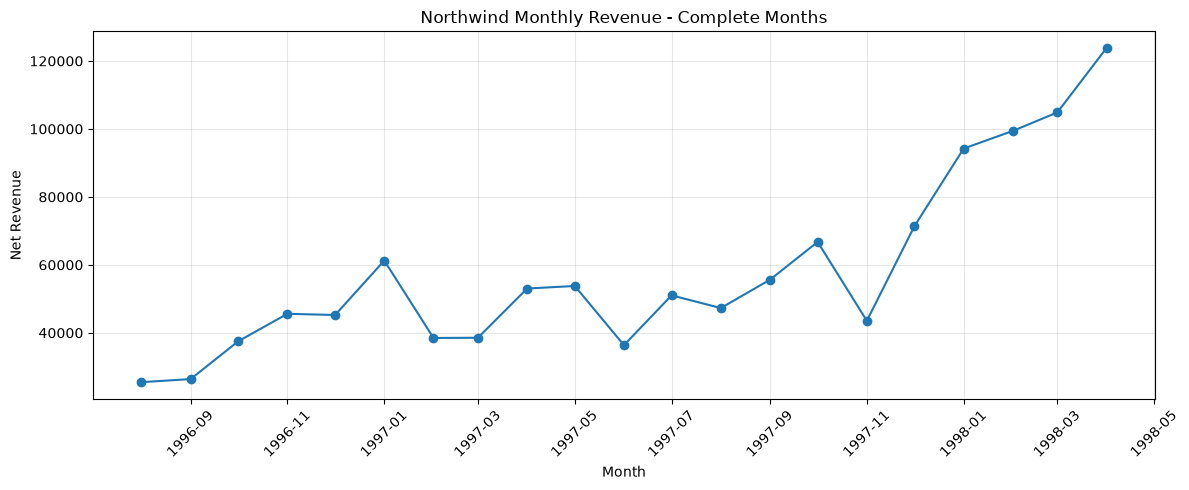

In [14]:
import matplotlib.pyplot as plt

# Exclude incomplete first and last months
complete_months = monthly_sales.iloc[1:-1].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    complete_months["month"].dt.to_timestamp(),
    complete_months["total_revenue"],
    marker="o"
)

plt.title("Northwind Monthly Revenue - Complete Months")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Aggregate sales by order
order_discount = (
    sales
    .groupby("order_id")
    .agg(
        total_units=("quantity", "sum"),
        has_discount=(
            "discount_rate",
            lambda x: (x > 0).any()
        ),
        net_revenue=("net_sales", "sum")
    )
    .reset_index()
)

# Compare discounted vs non-discounted orders
discount_summary = (
    order_discount
    .groupby("has_discount")
    .agg(
        orders=("order_id", "count"),
        avg_units=("total_units", "mean"),
        median_units=("total_units", "median"),
        avg_revenue=("net_revenue", "mean")
    )
    .reset_index()
)

print("Total orders:", len(order_discount))
display(discount_summary.round(2))

Total orders: 830


,has_discount,orders,avg_units,median_units,avg_revenue
0,False,450,52.44,35.0,1375.33
1,True,380,72.94,62.5,1702.35


In [16]:
import numpy as np

# Orders with discounts
group_a = order_discount.loc[
    order_discount["has_discount"], "total_units"
].to_numpy()

# Orders without discounts
group_b = order_discount.loc[
    ~order_discount["has_discount"], "total_units"
].to_numpy()

# Actual difference between group means
observed_diff = group_a.mean() - group_b.mean()

# Combine both groups
all_values = np.concatenate([group_a, group_b])

rng = np.random.default_rng(42)
count = 0
n_tests = 5000

# Randomly redistribute orders
for i in range(n_tests):
    shuffled = rng.permutation(all_values)

    diff = (
        shuffled[:len(group_a)].mean()
        - shuffled[len(group_a):].mean()
    )

    if abs(diff) >= abs(observed_diff):
        count += 1

p_value = (count + 1) / (n_tests + 1)

print("Difference:", round(observed_diff, 2))
print("P-value:", round(p_value, 4))

Difference: 20.5
P-value: 0.0002


In [17]:
import numpy as np

rng = np.random.default_rng(42)

bootstrap_diffs = []

for i in range(5000):
    sample_a = rng.choice(
        group_a, size=len(group_a), replace=True
    )

    sample_b = rng.choice(
        group_b, size=len(group_b), replace=True
    )

    diff = sample_a.mean() - sample_b.mean()
    bootstrap_diffs.append(diff)

ci_lower, ci_upper = np.percentile(
    bootstrap_diffs, [2.5, 97.5]
)

print(f"Observed difference: {observed_diff:.2f}")
print(f"95% Bootstrap CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

Observed difference: 20.50
95% Bootstrap CI: [13.63, 27.42]


In [18]:
# Calculate revenue per order and country
country_orders = (
    sales
    .groupby(["order_id", "ship_country"])
    .agg(
        order_revenue=("net_sales", "sum")
    )
    .reset_index()
)

# Calculate country statistics
country_summary = (
    country_orders
    .groupby("ship_country")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("order_revenue", "sum"),
        avg_order_value=("order_revenue", "mean")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

print("Total orders:", len(country_orders))
display(country_summary.head(10).round(2))

Total orders: 830


,ship_country,total_orders,total_revenue,avg_order_value
8,Germany,122,230284.69,1887.58
19,USA,122,245584.65,2012.99
3,Brazil,83,106925.79,1288.26
7,France,77,81358.33,1056.60
18,UK,56,58971.32,1053.06
20,Venezuela,46,56810.64,1235.01
1,Austria,40,128003.86,3200.10
16,Sweden,37,54495.16,1472.84
4,Canada,30,50196.31,1673.21
11,Mexico,28,23582.08,842.22


In [19]:
import numpy as np

# Select orders from USA and Germany
usa = country_orders.loc[
    country_orders["ship_country"] == "USA",
    "order_revenue"
].to_numpy()

germany = country_orders.loc[
    country_orders["ship_country"] == "Germany",
    "order_revenue"
].to_numpy()

# Calculate actual difference
observed_diff = usa.mean() - germany.mean()

# Combine both groups
all_orders = np.concatenate([usa, germany])

# Permutation test
rng = np.random.default_rng(42)
n_tests = 5000
count = 0

for i in range(n_tests):
    shuffled = rng.permutation(all_orders)

    diff = (
        shuffled[:len(usa)].mean()
        - shuffled[len(usa):].mean()
    )

    if abs(diff) >= abs(observed_diff):
        count += 1

p_value = (count + 1) / (n_tests + 1)

print("USA orders:", len(usa))
print("Germany orders:", len(germany))
print(f"Mean difference: {observed_diff:.2f}")
print(f"P-value: {p_value:.4f}")

USA orders: 122
Germany orders: 122
Mean difference: 125.41
P-value: 0.6845


In [20]:
import numpy as np

rng = np.random.default_rng(42)

country_bootstrap_diffs = []

for i in range(5000):
    sample_usa = rng.choice(
        usa, size=len(usa), replace=True
    )

    sample_germany = rng.choice(
        germany, size=len(germany), replace=True
    )

    diff = sample_usa.mean() - sample_germany.mean()
    country_bootstrap_diffs.append(diff)

ci_lower, ci_upper = np.percentile(
    country_bootstrap_diffs, [2.5, 97.5]
)

print(f"Observed difference: {observed_diff:.2f}")
print(f"95% Bootstrap CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

Observed difference: 125.41
95% Bootstrap CI: [-475.99, 711.56]


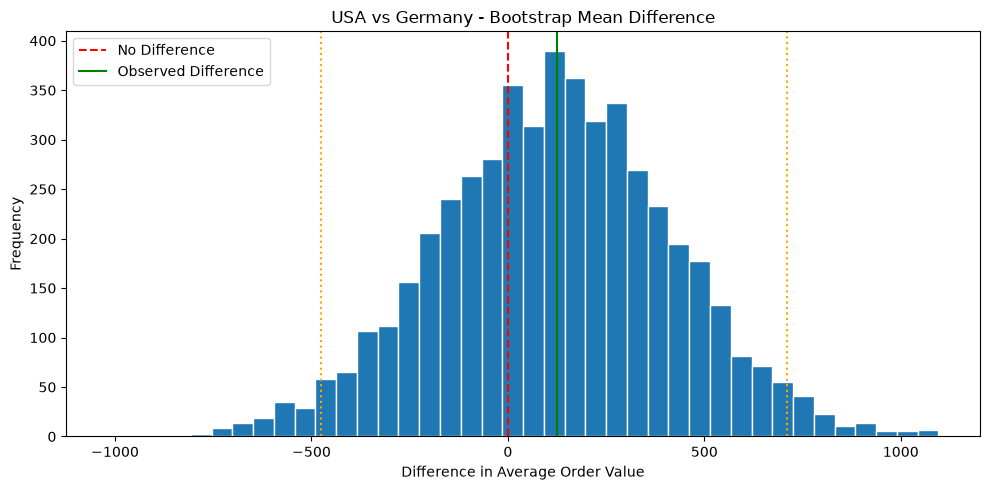

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Bootstrap distribution
plt.hist(
    country_bootstrap_diffs,
    bins=40,
    edgecolor="white"
)

# Zero difference
plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="No Difference"
)

# Observed difference
plt.axvline(
    observed_diff,
    color="green",
    label="Observed Difference"
)

# Confidence interval
plt.axvline(ci_lower, color="orange", linestyle=":")
plt.axvline(ci_upper, color="orange", linestyle=":")

plt.title("USA vs Germany - Bootstrap Mean Difference")
plt.xlabel("Difference in Average Order Value")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

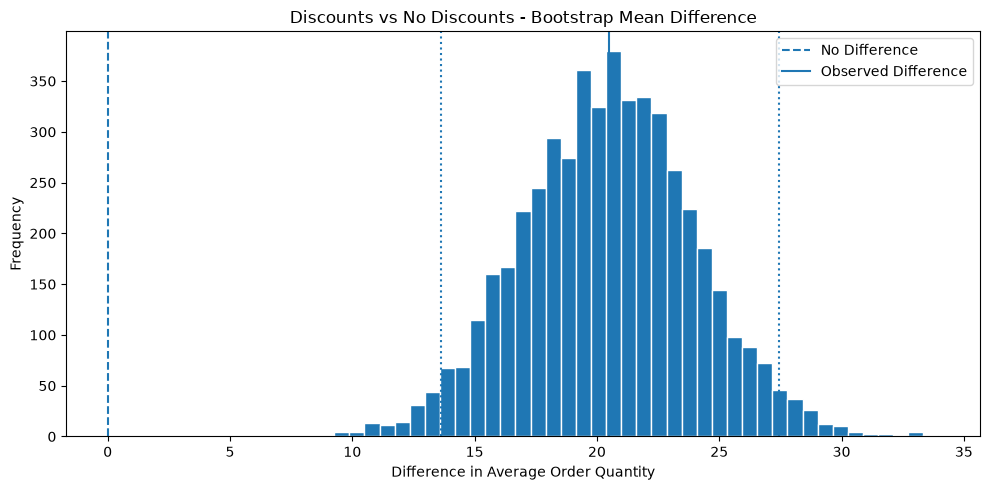

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Results from the first hypothesis
discount_diff = group_a.mean() - group_b.mean()

discount_ci = np.percentile(
    bootstrap_diffs, [2.5, 97.5]
)

plt.figure(figsize=(10, 5))

plt.hist(
    bootstrap_diffs,
    bins=40,
    edgecolor="white"
)

plt.axvline(0, linestyle="--", label="No Difference")
plt.axvline(discount_diff, label="Observed Difference")

plt.axvline(discount_ci[0], linestyle=":")
plt.axvline(discount_ci[1], linestyle=":")

plt.title("Discounts vs No Discounts - Bootstrap Mean Difference")
plt.xlabel("Difference in Average Order Quantity")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()


## Statistical Analysis — Business Findings

### Hypothesis 1: Discounts and Order Quantity

**Business Question:** Do orders with discounts contain more units?

**H0:** Mean order quantities are equal.

**H1:** Mean order quantities differ.

**Method:** Permutation Test (5,000 iterations) and Bootstrap Confidence Interval.

**Results:**
- Average units without discounts: 52.44
- Average units with discounts: 72.94
- Mean difference: 20.50 units
- P-value: 0.0002
- 95% CI: [13.63, 27.42]

**Conclusion:** We reject the null hypothesis at the 5% significance level. Discounted orders have significantly higher average quantities.

**Business Recommendation:** Investigate discount strategies further, but do not assume that discounts cause higher sales volumes.

### Hypothesis 2: USA vs Germany — Average Order Value

**Business Question:** Does Average Order Value differ between USA and Germany?

**H0:** USA and Germany have equal mean order values.

**H1:** USA and Germany have different mean order values.

**Method:** Permutation Test (5,000 iterations) and Bootstrap Confidence Interval.

**Results:**
- USA AOV: 2,012.99
- Germany AOV: 1,887.58
- Mean difference: 125.41
- P-value: 0.6845
- 95% CI: [-475.99, 711.56]

**Conclusion:** We fail to reject the null hypothesis. No statistically significant difference in average order value was detected between USA and Germany.

**Business Recommendation:** Do not prioritise one country over the other based on this AOV difference alone.

### Limitations

- Orders from the same customer may not be independent.
- Discounted orders may differ in other characteristics.
- Statistical association does not establish causation.
- Results are based on the available historical Northwind dataset.
- The first and last months contain incomplete data and should not be compared directly with full months.
- Larger orders may be more likely to contain at least one discounted product.
- Revenue does not equal profit; costs are not included in this analysis.

